### Setting seeds across PyThon, Numpy and PyTorch

In [68]:
import os

# Configure CUDA environment variable
# Set teh environment variable before initialising CUDA
# Set this variable before CUDA initialisation, ideally at the beginning of the Python scrip or the shell before launching Python.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

In [69]:
import random
import numpy as np
import torch

In [70]:
SEED = 42

# PyThon
random.seed(SEED)

# Numpy
np.random.seed(SEED)

# PyTorch CPU
torch.manual_seed(SEED)

# PyTorch GPU
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [71]:
# Combine the instructions into a reusable funtion

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

# Calling the function
set_seed(42)

### Enabling deterministic algorithms in Pytorch

In [72]:
torch.use_deterministic_algorithms(True)

### Configure cuDNN for deterministic operations

In [ ]:
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

### Configure CUDA environment variables

In [74]:
# Check the beginning of this script
# Code has been moved to the top of the notebook

### Weight initialisation (Randomly)

In [75]:
import torch.nn as nn
model = nn.Sequential(
    nn.Linear(10, 32),
    nn.ReLU(),
    nn.Linear(32, 2),
)

In [76]:
model = nn.Linear(10, 2)
# The weights and biases are initialised using random procedures

### Reproducibility in DataLoader

In [77]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Creating a synthetic dataset
dataset = datasets.FakeData(
    size=100,
    image_size=(3, 32, 32),
    num_classes=10,
    transform=transforms.ToTensor()
)

In [78]:
# Create a Data Loader
# This is another important source of randomness in the PyTorh DataLoader
# With shuffle=True, the dataset is shuffled before batches are generated.
loader = DataLoader(
    dataset=dataset,
    batch_size=32,
    shuffle=True 
)

print(loader)

In [79]:
# To make the shuffling reproduible, you may also create a dedicated random generator for the data loader

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = torch.utils.data.DataLoader(
    dataset=dataset,
    batch_size=64,
    shuffle=True,
    generator=generator
)

# The above makes the data sampling sequence reproducible when the generator is reset to the same state.

### Configuring Number of Workers with Reproducibility

In [80]:
# Initialise the workers consistently
# Each worker may have its own random state. THis matters particularly when performing random transformations inside dataset workers

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

In [81]:
generator = torch.Generator()
generator.manual_seed(42)

train_loader = DataLoader(
    dataset=dataset,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    worker_init_fn=seed_worker,
    generator=generator
)

# The above ensures that worker random states are derived onsistently from teh DataLoader generator.

### Reproducibility in Data Augmentation

In [ ]:
# Iterate through the dataset
for images, labels in train_loader:
    print(f"Images: {images.shape}")
    print(f"Labels: ", labels)

Images: torch.Size([64, 3, 32, 32])
Labels:  tensor([0, 6, 1, 8, 5, 2, 7, 3, 7, 0, 3, 6, 7, 9, 3, 1, 0, 6, 8, 2, 7, 3, 4, 7,
        7, 4, 1, 3, 1, 5, 6, 4, 7, 9, 3, 3, 3, 6, 9, 9, 0, 7, 0, 4, 2, 6, 3, 1,
        9, 3, 1, 8, 4, 1, 3, 4, 6, 0, 9, 9, 0, 8, 8, 6])
Images: torch.Size([36, 3, 32, 32])
Labels:  tensor([0, 5, 4, 9, 1, 6, 6, 3, 8, 2, 5, 4, 9, 1, 2, 1, 1, 7, 1, 6, 4, 4, 7, 7,
        1, 2, 0, 3, 5, 9, 5, 8, 1, 3, 7, 1])


In [83]:
# To understand randomness in the above, compare the order of samples across multiple iterations (epochs)

from torch.utils.data import TensorDataset

# Create 100 samples
features = torch.arange(100).unsqueeze(1)
labels = torch.arange(100)

print(features[:10])
print(labels[:10])

tensor([[0],
        [1],
        [2],
        [3],
        [4],
        [5],
        [6],
        [7],
        [8],
        [9]])
tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])


In [84]:
# Create a dataset instance
dataset = TensorDataset(features, labels)

# Create DataLoader
loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

# Test three epochs
for epoch in range(3):
    print(f"\nEpoch {epoch + 1}")

    for features, labels in loader:
        print(labels.tolist())


Epoch 1
[97, 45, 39, 2, 96, 82, 17, 38, 52, 58, 64, 28, 24, 20, 41, 57, 22, 1, 33, 34, 12, 31, 25, 88, 67, 95, 66, 54, 70, 90, 47, 23]
[42, 71, 53, 72, 94, 16, 78, 68, 99, 43, 37, 98, 0, 92, 29, 65, 73, 40, 5, 83, 7, 3, 61, 19, 27, 15, 10, 75, 26, 44, 30, 6]
[9, 87, 49, 46, 55, 8, 51, 36, 18, 91, 14, 11, 60, 79, 4, 74, 32, 21, 50, 81, 59, 77, 63, 13, 85, 93, 56, 84, 48, 86, 62, 76]
[80, 69, 35, 89]

Epoch 2
[84, 8, 24, 72, 14, 2, 60, 15, 56, 20, 93, 87, 33, 76, 16, 59, 49, 67, 19, 5, 47, 63, 36, 4, 11, 77, 40, 48, 68, 51, 38, 99]
[50, 23, 86, 66, 53, 0, 17, 29, 91, 81, 61, 71, 58, 70, 62, 13, 74, 21, 54, 10, 30, 6, 85, 55, 44, 64, 73, 96, 88, 57, 97, 65]
[7, 42, 31, 94, 75, 41, 27, 26, 80, 9, 22, 43, 83, 39, 35, 28, 82, 12, 18, 78, 52, 1, 89, 34, 92, 69, 45, 37, 46, 25, 95, 32]
[90, 79, 98, 3]

Epoch 3
[64, 23, 87, 33, 53, 8, 56, 19, 45, 4, 77, 81, 26, 88, 1, 47, 51, 39, 61, 31, 17, 80, 43, 78, 35, 44, 24, 52, 30, 91, 72, 84]
[97, 46, 6, 67, 76, 32, 82, 3, 65, 25, 59, 36, 42, 20, 38, 

### Random Data Augmentation

In [85]:
from torchvision import transforms
import matplotlib.pyplot as plt

In [86]:
dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

0


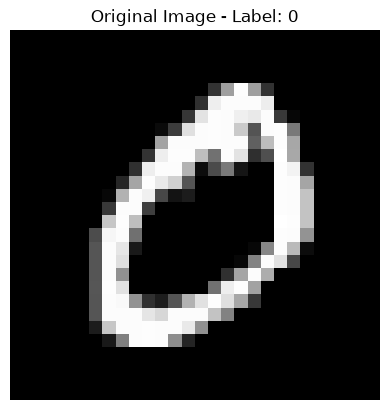

In [87]:
image, label = dataset[1]
print(label)

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Original Image - Label: {label}")
plt.axis("Off")
plt.show()

In [88]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15)
]
)


In [89]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):

    transformed_image = transform(image)

    axes[i].imshow(transformed_image.squeeze(), cmap="gray")
    axes[i].set_title(f"Transformation {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

KeyboardInterrupt: 